Explorational Analysis

In [1]:
import logging

import matplotlib.pyplot as plt
import pandas as pd

from cwfc.split import split_holdout
from cwfc.targets import build_targets

logging.basicConfig(level=logging.INFO)

readings = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
metadata = pd.read_csv("../challenge_data/vm_metadata.csv.gz")

targets = build_targets(readings)
train, holdout_timestamps = split_holdout(targets)

train_readings = readings[readings["timestamp"].isin(train["timestamp"])]

INFO:cwfc.targets:Dropped 0 of 1340000 rows


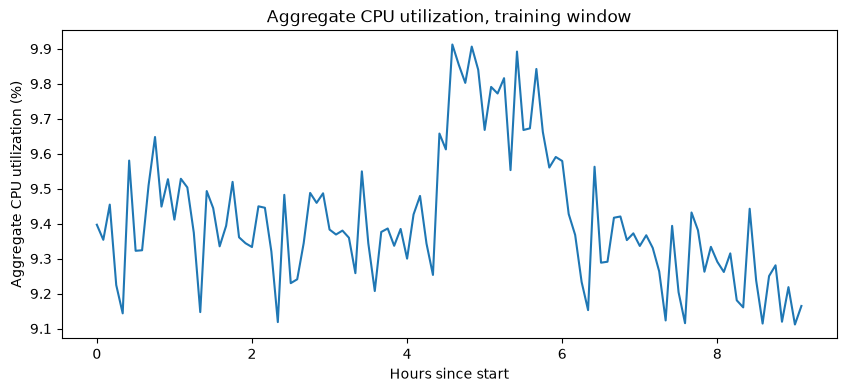

In [2]:
hours = train["timestamp"] / 3600

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hours, train["aggregate_cpu_utilization"])
ax.set_xlabel("Hours since start")
ax.set_ylabel("Aggregate CPU utilization (%)")
ax.set_title("Aggregate CPU utilization, training window")
plt.show()

In [3]:
train.iloc[40:56][["timestamp", "aggregate_cpu_utilization"]]

,timestamp,aggregate_cpu_utilization
40,12000,9.258377
41,12300,9.549447
42,12600,9.343735
43,12900,9.207312
44,13200,9.376121
45,13500,9.386168
46,13800,9.336650
47,14100,9.384814
48,14400,9.299893
49,14700,9.426354


In [4]:
train.loc[train["aggregate_cpu_utilization"].idxmax()]

timestamp                    16500.000000
active_vm_count              10000.000000
aggregate_cpu_utilization        9.912175
Name: 55, dtype: float64

In [5]:
train["aggregate_cpu_utilization"].median()

np.float64(9.378120946203444)

In [6]:
hours_r = train_readings["timestamp"] / 3600
in_spike = hours_r.between(4, 6)

per_vm = train_readings.groupby(["vm_id", in_spike])["avg_cpu"].mean().unstack()
increase = (per_vm[True] - per_vm[False]).sort_values(ascending=False)

share_top = increase.head(10).sum() / increase.sum()
share_top

np.float64(0.14142693517167107)

In [7]:
increase.head(100).sum() / increase.sum()

np.float64(0.7842163064379386)

Finding: Aggregate CPU stays in a narrow band around its median of 9.38% with no visible trend: the level before hour 4 and after hour 6 is about the same. The largest deviation is a bump between hours 4 and 6, peaking at 9.91% at hour 4.6 (step 55), about 0.53 points (~6%) above the median. A slow rise precedes it, but the jump itself is abrupt.

The bump is driven by a small group of VMs: comparing each VM’s mean CPU inside and outside that window, the top 10 VMs (0.1%) account for about 14% of the increase and the top 100 (1%) for about 78%.

Why it matters: Bursts from a few workloads give only a weak early signal in the aggregate history, so a forecast based on past values will tend to under-predict them. The capacity margin should therefore come from the forecast’s uncertainty, not from the point forecast alone.

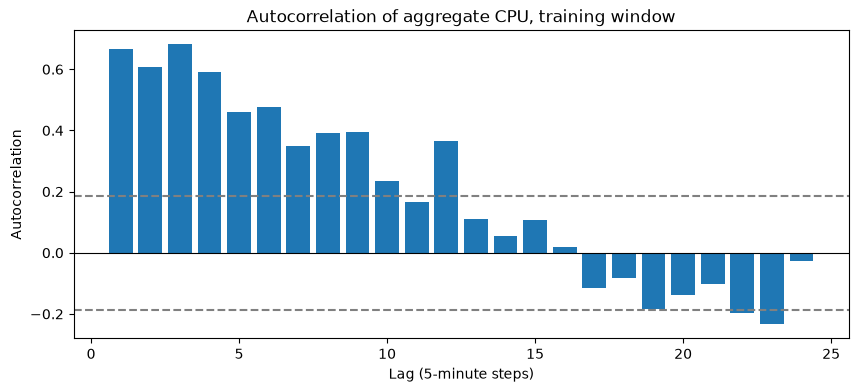

1     0.67
2     0.61
3     0.68
4     0.59
5     0.46
6     0.48
7     0.35
8     0.39
9     0.40
10    0.23
11    0.17
12    0.37
13    0.11
14    0.05
15    0.11
16    0.02
17   -0.11
18   -0.08
19   -0.18
20   -0.14
21   -0.10
22   -0.20
23   -0.23
24   -0.03
dtype: float64

In [8]:
series = train["aggregate_cpu_utilization"]
lags = range(1, 25)
acf = [series.autocorr(lag=k) for k in lags]

band = 1.96 / len(series) ** 0.5   # ~95% band for "no correlation"

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(lags, acf)
ax.axhline(band, color="grey", linestyle="--")
ax.axhline(-band, color="grey", linestyle="--")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Lag (5-minute steps)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Autocorrelation of aggregate CPU, training window")
plt.show()

pd.Series(acf, index=lags).round(2)

Finding: Autocorrelation is about 0.7 at lag 1 (5 minutes) and declines gradually, falling inside the ±0.19 no-correlation band from around lag 15 (75 minutes) onwards.

Why it matters: Recent values carry useful information for the next few steps, but almost none for 2 hours ahead (lag 24). Persistence should win at short horizons and the mean at long ones, so baselines are compared per horizon step, and a forecast that starts at the last value and moves towards the mean is a natural simple model.

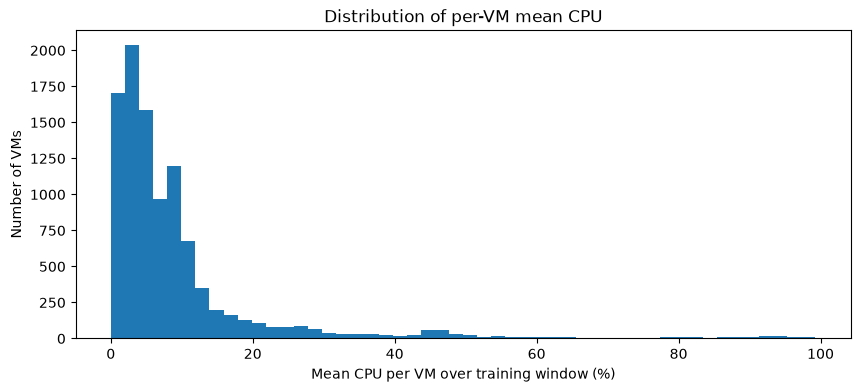

count    10000.00
mean         9.41
std         13.05
min          0.01
50%          5.50
90%         19.74
99%         79.62
max         99.27
Name: avg_cpu, dtype: float64

In [9]:
per_vm_mean = train_readings.groupby("vm_id")["avg_cpu"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(per_vm_mean, bins=50)
ax.set_xlabel("Mean CPU per VM over training window (%)")
ax.set_ylabel("Number of VMs")
ax.set_title("Distribution of per-VM mean CPU")
plt.show()

per_vm_mean.describe(percentiles=[0.5, 0.9, 0.99]).round(2)

In [10]:
(per_vm_mean > 50).mean()

np.float64(0.022)

Finding: Per-VM mean CPU is highly skewed: the median VM uses 5.5%, 90% of VMs stay below 19.7%, but the top 1% run at about 99% and only 2.2% average above 50%. The aggregate mean (9.4%) is pulled up by this small group and does not represent a typical VM.

Why it matters: Most VMs look heavily over-provisioned, which suggests a large right-sizing opportunity, while capacity risk is concentrated in a small group of near-saturated VMs, the same pattern as in the hour 4–6 bump. CPU is only one dimension: a VM’s size may be driven by memory, so low CPU alone does not prove it is oversized.

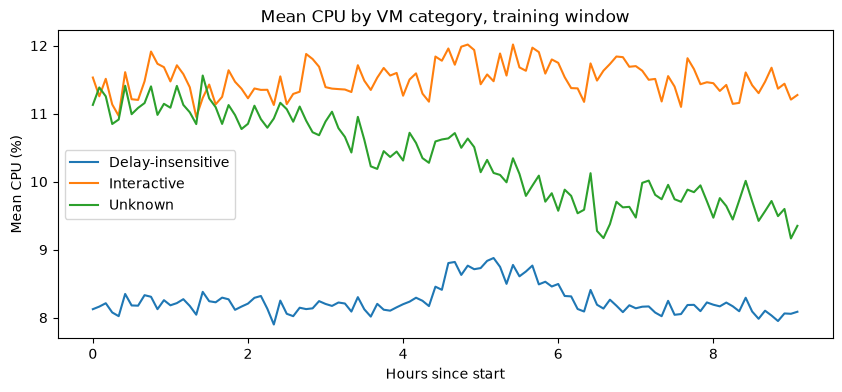

vm_category,Delay-insensitive,Interactive,Unknown
count,110.00,110.00,110.00
mean,8.26,11.51,10.35
std,0.22,0.24,0.63
min,7.90,10.95,9.17
25%,8.12,11.35,9.77
50%,8.19,11.49,10.35
75%,8.31,11.68,10.91
max,8.88,12.02,11.56


In [11]:
seg = train_readings.merge(metadata[["vm_id", "vm_category"]], on="vm_id")
seg_series = seg.groupby(["timestamp", "vm_category"])["avg_cpu"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 4))
for cat in seg_series.columns:
    ax.plot(seg_series.index / 3600, seg_series[cat], label=cat)
ax.set_xlabel("Hours since start")
ax.set_ylabel("Mean CPU (%)")
ax.set_title("Mean CPU by VM category, training window")
ax.legend()
plt.show()

seg_series.describe().round(2)

In [12]:
summary = pd.DataFrame({
    "mean": seg_series.mean(),
    "std": seg_series.std(),
    "min": seg_series.min(),
    "max": seg_series.max(),
    "first_hour": seg_series.iloc[:12].mean(),
    "last_hour": seg_series.iloc[-12:].mean(),
    "peak_hour": seg_series.idxmax() / 3600,
}).round(2)
summary

,mean,std,min,max,first_hour,last_hour,peak_hour
vm_category,,,,,,,
Delay-insensitive,8.26,0.22,7.90,8.88,8.19,8.10,5.17
Interactive,11.51,0.24,10.95,12.02,11.44,11.37,5.42
Unknown,10.35,0.63,9.17,11.56,11.14,9.57,1.42


Finding: The three categories differ clearly. Interactive VMs have the highest mean CPU (11.51%) and Delay-insensitive the lowest (8.26%). Unknown is about three times as volatile as the others (std 0.63 vs ~0.23) and is the only category with a clear downward trend (11.14% → 9.57%). The hour 4–6 bump appears in both Interactive and Delay-insensitive at the same time (hours 5.2–5.4), but not in Unknown.

Why it matters: The aggregate series mostly follows Delay-insensitive (correlation 0.93), which holds 62% of the VMs, so it hides the different behaviour of the other categories.

In [13]:
step_change = train["aggregate_cpu_utilization"].diff()

print(step_change.describe().round(3))
print("Largest rise:", round(step_change.max(), 3), "at hour", train.loc[step_change.idxmax(), "timestamp"] / 3600)
print("Largest drop:", round(step_change.min(), 3), "at hour", train.loc[step_change.idxmin(), "timestamp"] / 3600)

count    109.000
mean      -0.002
std        0.158
min       -0.274
25%       -0.109
50%       -0.020
75%        0.078
max        0.437
Name: aggregate_cpu_utilization, dtype: float64
Largest rise: 0.437 at hour 0.4166666666666667
Largest drop: -0.274 at hour 6.5


Finding: Step-to-step changes in aggregate CPU are small: the standard deviation is 0.16 points (about 1.7% of the level) and the largest single rise is 0.44 points (about 4.7%).

Why it matters: No large surprise is expected within a single 5-minute step. The risk for a 2-hour forecast comes from small changes accumulating over many steps, as in the hour 4–6 bump, rather than from sudden jumps.